Appareil utilisé : cpu
Forme de X : (100, 2) | data_dim = 2 | hidden_dim = 10


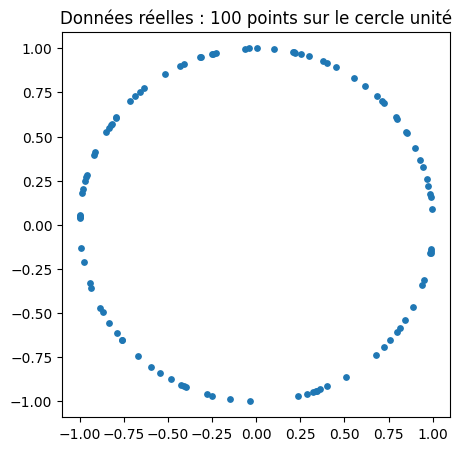

Sequential(
  (0): Linear(in_features=10, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=2, bias=True)
)
Sequential(
  (0): Linear(in_features=2, out_features=32, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): LeakyReLU(negative_slope=0.2)
  (4): Linear(in_features=32, out_features=1, bias=True)
  (5): Sigmoid()
)
G(z) : torch.Size([5, 2]) | D(G(z)) : [0.514 0.512 0.509 0.51  0.509]
Paramètres G : 1474 | Paramètres D : 1185


In [1]:
# =====================================================
# TP 3 — Generative Adversarial Networks (GAN)
# Imports
# =====================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets                     # jeux jouets : demi-lunes, Swiss roll

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

# =====================================================
# 1.2 — Jeu de données jouet : points sur le cercle unité (code de l'énoncé)
# =====================================================
np.random.seed(0)
X = np.random.randn(100, 2)
X /= np.linalg.norm(X, axis=1)[:, None].repeat(2, axis=1)   # chaque point est divisé par sa norme -> cercle
data_dim = X.shape[-1]                           # 2
hidden_dim = 10                                  # dimension de l'espace latent
X_tensor = torch.tensor(X, dtype=torch.float32)
print("Forme de X :", X.shape, "| data_dim =", data_dim, "| hidden_dim =", hidden_dim)

plt.figure(figsize=(5, 5)); plt.scatter(X[:, 0], X[:, 1], s=15)
plt.axis("equal"); plt.title("Données réelles : 100 points sur le cercle unité"); plt.show()

# =====================================================
# Question 1 — Architectures de G et D (nn.Sequential)
# =====================================================
def creer_modeles(data_dim, hidden_dim, taille_cachee=32):
    # a) Générateur : 3 couches entièrement connectées, z (hidden_dim) -> échantillon (data_dim)
    G = nn.Sequential(
        nn.Linear(hidden_dim, taille_cachee), nn.ReLU(),
        nn.Linear(taille_cachee, taille_cachee), nn.ReLU(),
        nn.Linear(taille_cachee, data_dim))      # pas d'activation : coordonnées libres
    # b) Discriminateur : donnée -> probabilité d'être réelle (sigmoïde)
    D = nn.Sequential(
        nn.Linear(data_dim, taille_cachee), nn.LeakyReLU(0.2),
        nn.Linear(taille_cachee, taille_cachee), nn.LeakyReLU(0.2),
        nn.Linear(taille_cachee, 1), nn.Sigmoid())
    return G, D

torch.manual_seed(0)
G, D = creer_modeles(data_dim, hidden_dim)
print(G); print(D)
z = torch.randn(5, hidden_dim)
print("G(z) :", G(z).shape, "| D(G(z)) :", D(G(z)).detach().squeeze().numpy().round(3))
print("Paramètres G :", sum(p.numel() for p in G.parameters()), "| Paramètres D :", sum(p.numel() for p in D.parameters()))

Itération  1000 | loss_D = 1.343 | loss_G = -0.667 | D(x) = 0.51 | D(G(z)) = 0.49
Itération  2000 | loss_D = 1.366 | loss_G = -0.672 | D(x) = 0.50 | D(G(z)) = 0.49
Itération  3000 | loss_D = 1.383 | loss_G = -0.679 | D(x) = 0.49 | D(G(z)) = 0.49
Itération  4000 | loss_D = 1.380 | loss_G = -0.689 | D(x) = 0.51 | D(G(z)) = 0.50
Itération  5000 | loss_D = 1.381 | loss_G = -0.688 | D(x) = 0.50 | D(G(z)) = 0.50


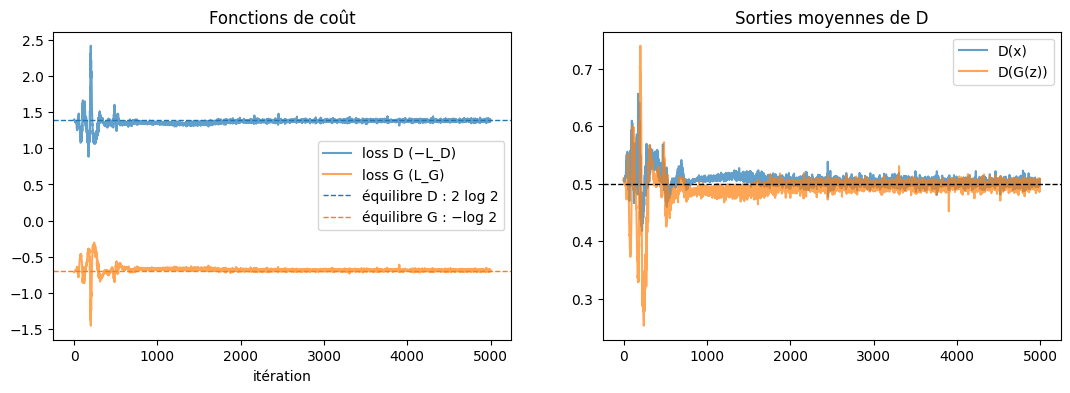

Norme moyenne des points générés : 0.988 | écart-type : 0.039 (cercle réel : 1 et 0)


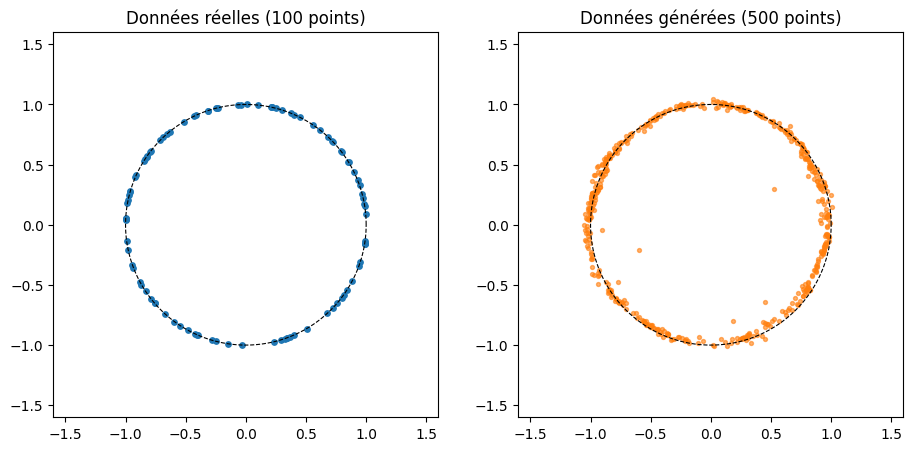

Classés 'real' : 234/500 (46.8 %) | D(x̂) : min = 0.344, moyenne = 0.500, max = 0.550


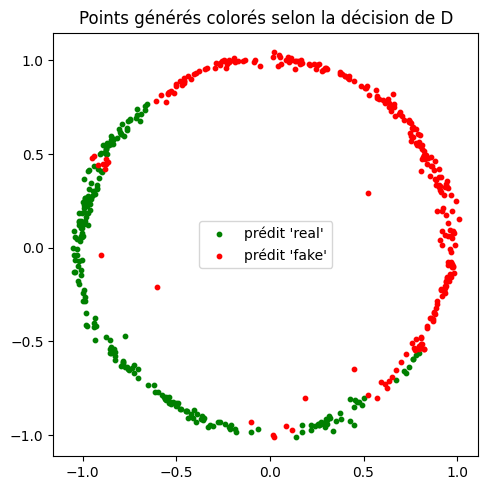

In [2]:
# =====================================================
# Question 2 — Boucle d'apprentissage du GAN
# D maximise L_D = log D(x) + log(1 - D(G(z)))   -> on minimise -L_D
# G minimise L_G = log(1 - D(G(z)))
# =====================================================
def entrainer_gan(G, D, X_tensor, hidden_dim, nb_iterations=5000, batch_size=32, lr=1e-3):
    opt_D = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_G = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    eps = 1e-8                                    # évite log(0)
    hist = {"loss_D": [], "loss_G": [], "D_reel": [], "D_faux": []}
    for it in range(nb_iterations):
        x_reel = X_tensor[torch.randint(0, len(X_tensor), (batch_size,))]   # 1. batch de données réelles
        z = torch.randn(batch_size, hidden_dim)                             # 2. bruit z ~ N(0, 1)
        x_faux = G(z)                                                       # 3. fausses données G(z)
        d_reel = D(x_reel)
        d_faux = D(x_faux.detach())                                         # detach() : pas de gradient vers G
        loss_D = -(torch.log(d_reel + eps) + torch.log(1 - d_faux + eps)).mean()   # 4. coût de D
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()                  # 5. pas d'optimisation de D
        loss_G = torch.log(1 - D(x_faux) + eps).mean()                      # 6. coût de G (sans detach)
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()                  # 7. pas d'optimisation de G
        hist["loss_D"].append(loss_D.item()); hist["loss_G"].append(loss_G.item())
        hist["D_reel"].append(d_reel.mean().item()); hist["D_faux"].append(d_faux.mean().item())
        if (it + 1) % 1000 == 0:
            print(f"Itération {it+1:5d} | loss_D = {loss_D.item():.3f} | loss_G = {loss_G.item():.3f} "
                  f"| D(x) = {hist['D_reel'][-1]:.2f} | D(G(z)) = {hist['D_faux'][-1]:.2f}")
    return hist

torch.manual_seed(0)
G, D = creer_modeles(data_dim, hidden_dim)
hist = entrainer_gan(G, D, X_tensor, hidden_dim)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist["loss_D"], alpha=0.7, label="loss D (−L_D)"); ax[0].plot(hist["loss_G"], alpha=0.7, label="loss G (L_G)")
ax[0].axhline(2 * np.log(2), color="C0", ls="--", lw=1, label="équilibre D : 2 log 2")
ax[0].axhline(-np.log(2), color="C1", ls="--", lw=1, label="équilibre G : −log 2")
ax[0].set_title("Fonctions de coût"); ax[0].set_xlabel("itération"); ax[0].legend()
ax[1].plot(hist["D_reel"], alpha=0.7, label="D(x)"); ax[1].plot(hist["D_faux"], alpha=0.7, label="D(G(z))")
ax[1].axhline(0.5, color="k", ls="--", lw=1); ax[1].set_title("Sorties moyennes de D"); ax[1].legend()
plt.show()

# =====================================================
# Question 3 — Visualisation des points générés (réel vs synthétique)
# =====================================================
torch.manual_seed(1)
with torch.no_grad():
    X_gen = G(torch.randn(500, hidden_dim)).numpy()
normes = np.linalg.norm(X_gen, axis=1)
print(f"Norme moyenne des points générés : {normes.mean():.3f} | écart-type : {normes.std():.3f} (cercle réel : 1 et 0)")
theta = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].scatter(X[:, 0], X[:, 1], s=15); ax[0].set_title("Données réelles (100 points)")
ax[1].scatter(X_gen[:, 0], X_gen[:, 1], s=8, color="C1", alpha=0.6); ax[1].set_title("Données générées (500 points)")
for a in ax:
    a.plot(np.cos(theta), np.sin(theta), "k--", lw=0.8); a.set_xlim(-1.6, 1.6); a.set_ylim(-1.6, 1.6); a.set_aspect("equal")
plt.show()

# =====================================================
# Question 4 — Décision du discriminateur (seuil 0.5)
# =====================================================
with torch.no_grad():
    p_gen = D(torch.tensor(X_gen, dtype=torch.float32)).squeeze().numpy()
reel = p_gen >= 0.5
print(f"Classés 'real' : {reel.sum()}/500 ({100*reel.mean():.1f} %) | D(x̂) : min = {p_gen.min():.3f}, "
      f"moyenne = {p_gen.mean():.3f}, max = {p_gen.max():.3f}")
plt.figure(figsize=(5.5, 5.5))
plt.scatter(X_gen[reel, 0], X_gen[reel, 1], s=10, color="green", label="prédit 'real'")
plt.scatter(X_gen[~reel, 0], X_gen[~reel, 1], s=10, color="red", label="prédit 'fake'")
plt.gca().set_aspect("equal"); plt.legend(); plt.title("Points générés colorés selon la décision de D")
plt.show()

===== Demi-lunes =====
Itération  1000 | loss_D = 1.367 | loss_G = -0.672 | D(x) = 0.50 | D(G(z)) = 0.49
Itération  2000 | loss_D = 1.385 | loss_G = -0.699 | D(x) = 0.51 | D(G(z)) = 0.51
Itération  3000 | loss_D = 1.388 | loss_G = -0.677 | D(x) = 0.49 | D(G(z)) = 0.49
Itération  4000 | loss_D = 1.382 | loss_G = -0.686 | D(x) = 0.51 | D(G(z)) = 0.51
Itération  5000 | loss_D = 1.386 | loss_G = -0.707 | D(x) = 0.50 | D(G(z)) = 0.50
Itération  6000 | loss_D = 1.385 | loss_G = -0.699 | D(x) = 0.50 | D(G(z)) = 0.50
Itération  7000 | loss_D = 1.387 | loss_G = -0.691 | D(x) = 0.50 | D(G(z)) = 0.50
Itération  8000 | loss_D = 1.389 | loss_G = -0.699 | D(x) = 0.50 | D(G(z)) = 0.51
Q4 demi-lunes — classés 'real' : 815/1000 | D(x̂) moyenne = 0.504


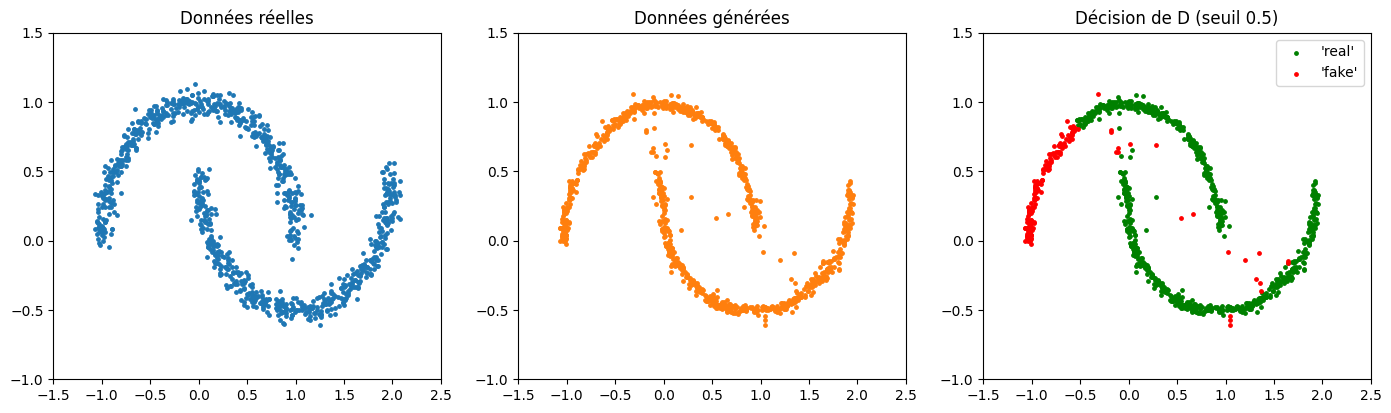


===== Swiss roll, dimension latente = 10 =====
Itération  1000 | loss_D = 1.372 | loss_G = -0.684 | D(x) = 0.50 | D(G(z)) = 0.49
Itération  2000 | loss_D = 1.379 | loss_G = -0.645 | D(x) = 0.48 | D(G(z)) = 0.48
Itération  3000 | loss_D = 1.378 | loss_G = -0.685 | D(x) = 0.51 | D(G(z)) = 0.50
Itération  4000 | loss_D = 1.376 | loss_G = -0.689 | D(x) = 0.51 | D(G(z)) = 0.50
Itération  5000 | loss_D = 1.385 | loss_G = -0.674 | D(x) = 0.49 | D(G(z)) = 0.49
Itération  6000 | loss_D = 1.382 | loss_G = -0.669 | D(x) = 0.49 | D(G(z)) = 0.49
Itération  7000 | loss_D = 1.396 | loss_G = -0.630 | D(x) = 0.48 | D(G(z)) = 0.49
Itération  8000 | loss_D = 1.380 | loss_G = -0.716 | D(x) = 0.52 | D(G(z)) = 0.52

===== Swiss roll, dimension latente = 2 =====
Itération  1000 | loss_D = 1.389 | loss_G = -0.670 | D(x) = 0.50 | D(G(z)) = 0.49
Itération  2000 | loss_D = 1.383 | loss_G = -0.675 | D(x) = 0.49 | D(G(z)) = 0.49
Itération  3000 | loss_D = 1.415 | loss_G = -0.724 | D(x) = 0.51 | D(G(z)) = 0.52
Ité

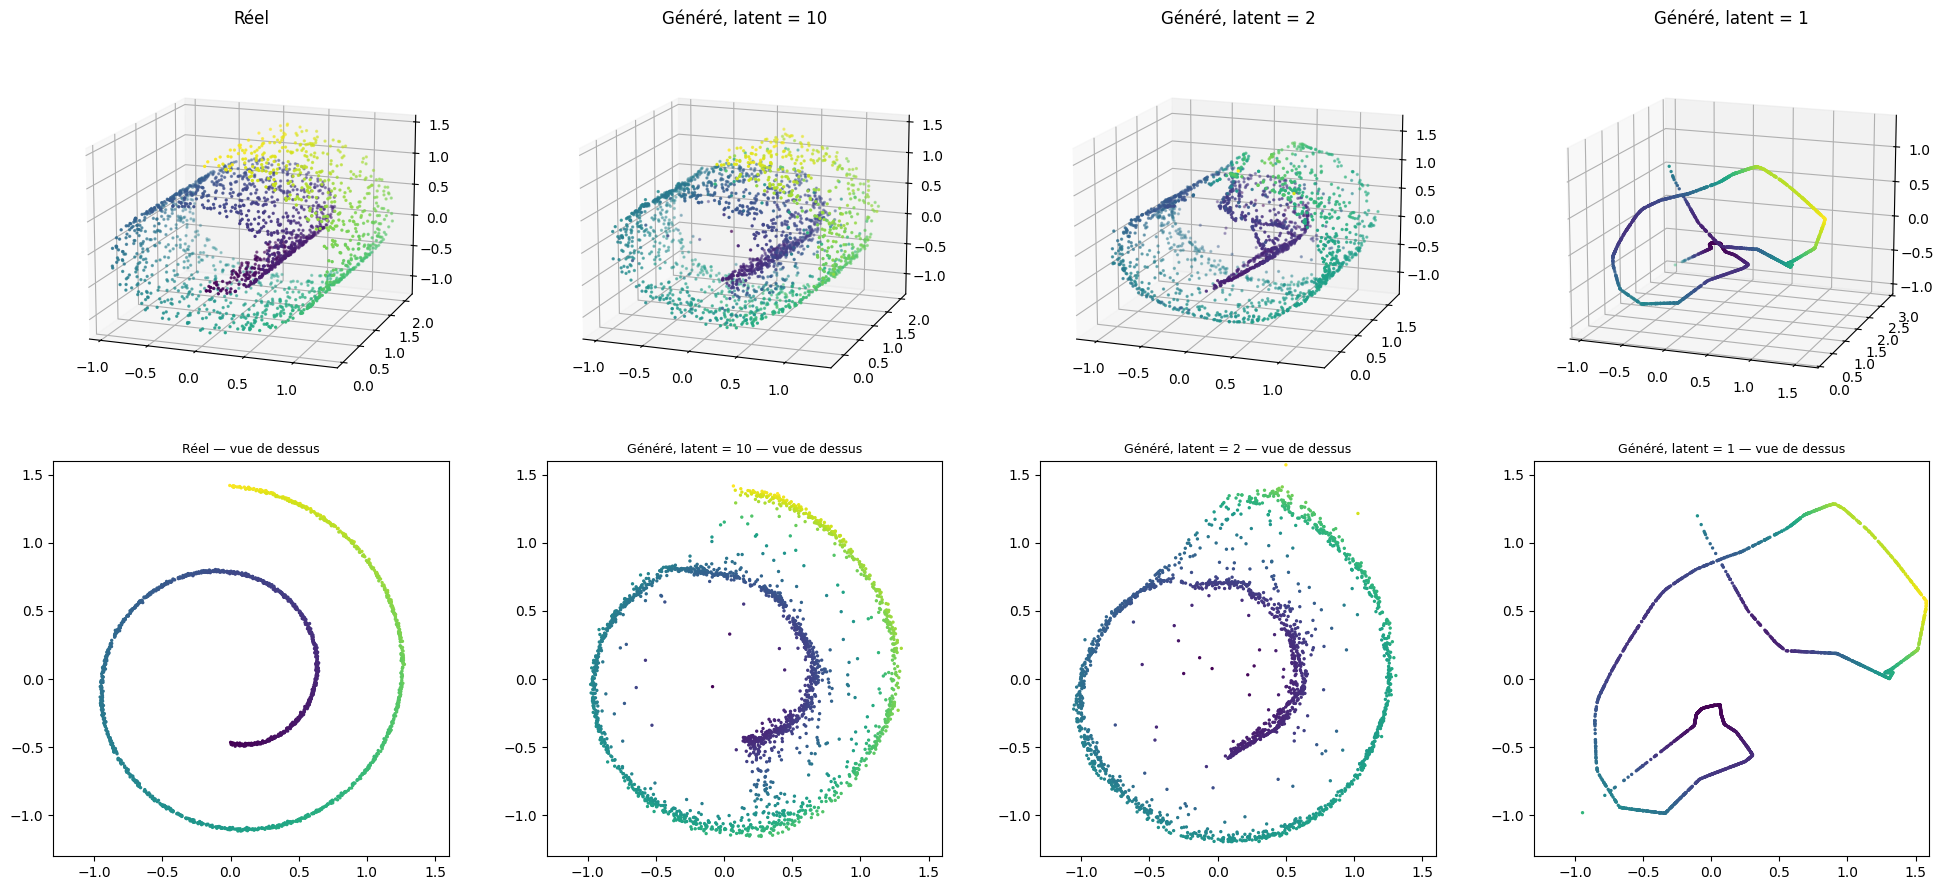

In [3]:
# =====================================================
# Question 5 (optionnelle) — Jeu de données : deux demi-lunes
# =====================================================
X_moons, y_moons = datasets.make_moons(n_samples=1000, noise=0.05, random_state=0)
X_moons_t = torch.tensor(X_moons, dtype=torch.float32)
torch.manual_seed(0)
G_m, D_m = creer_modeles(2, hidden_dim, taille_cachee=64)
print("===== Demi-lunes =====")
entrainer_gan(G_m, D_m, X_moons_t, hidden_dim, nb_iterations=8000, batch_size=64)
torch.manual_seed(1)
with torch.no_grad():
    X_gen_m = G_m(torch.randn(1000, hidden_dim)).numpy()
    p_m = D_m(torch.tensor(X_gen_m, dtype=torch.float32)).squeeze().numpy()
r_m = p_m >= 0.5
print(f"Q4 demi-lunes — classés 'real' : {r_m.sum()}/1000 | D(x̂) moyenne = {p_m.mean():.3f}")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(X_moons[:, 0], X_moons[:, 1], s=6); ax[0].set_title("Données réelles")
ax[1].scatter(X_gen_m[:, 0], X_gen_m[:, 1], s=6, color="C1"); ax[1].set_title("Données générées")
ax[2].scatter(X_gen_m[r_m, 0], X_gen_m[r_m, 1], s=6, color="green", label="'real'")
ax[2].scatter(X_gen_m[~r_m, 0], X_gen_m[~r_m, 1], s=6, color="red", label="'fake'")
ax[2].set_title("Décision de D (seuil 0.5)"); ax[2].legend()
for a in ax: a.set_xlim(-1.5, 2.5); a.set_ylim(-1, 1.5)
plt.show()

# =====================================================
# Question 6 (optionnelle) — Swiss roll : effet de la dimension de l'espace latent
# =====================================================
X_sr, _ = datasets.make_swiss_roll(n_samples=2000, noise=0.05, random_state=0)
X_sr = X_sr / 10.0                               # mise à l'échelle pour faciliter l'entraînement
X_sr_t = torch.tensor(X_sr, dtype=torch.float32)
generations = {}
for dz in [10, 2, 1]:
    print(f"\n===== Swiss roll, dimension latente = {dz} =====")
    torch.manual_seed(0)
    G_s, D_s = creer_modeles(3, dz, taille_cachee=64)
    entrainer_gan(G_s, D_s, X_sr_t, dz, nb_iterations=8000, batch_size=128)
    with torch.no_grad():
        generations[dz] = G_s(torch.randn(2000, dz)).numpy()

nuages = [("Réel", X_sr)] + [(f"Généré, latent = {dz}", generations[dz]) for dz in [10, 2, 1]]
fig = plt.figure(figsize=(20, 9))
for k, (titre, P) in enumerate(nuages):
    couleur = P[:, 0] ** 2 + P[:, 2] ** 2
    a3 = fig.add_subplot(2, 4, k + 1, projection="3d")
    a3.scatter(P[:, 0], P[:, 1], P[:, 2], s=2, c=couleur, cmap="viridis"); a3.set_title(titre); a3.view_init(15, -70)
    a2 = fig.add_subplot(2, 4, k + 5)
    a2.scatter(P[:, 0], P[:, 2], s=2, c=couleur, cmap="viridis"); a2.set_title(titre + " — vue de dessus", fontsize=9)
    a2.set_xlim(-1.3, 1.6); a2.set_ylim(-1.3, 1.6); a2.set_aspect("equal")
plt.tight_layout(); plt.show()

# Constat : avec une dimension latente de 10 ou 2, le GAN reproduit la surface enroulée et l'entraînement
# reste à l'équilibre. Avec une dimension latente de 1, G ne peut produire qu'une courbe (objet de
# dimension 1), alors que le Swiss roll est une surface (dimension 2) : il ne couvre pas toute la largeur
# du rouleau et l'entraînement devient instable (les pertes oscillent, D distingue en partie le vrai du
# faux). La dimension latente doit être au moins égale à la dimension intrinsèque des données.

Appareil utilisé : cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 503kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.1MB/s]


Époque  1/30 | loss_D = 1.089 | loss_G = 1.141


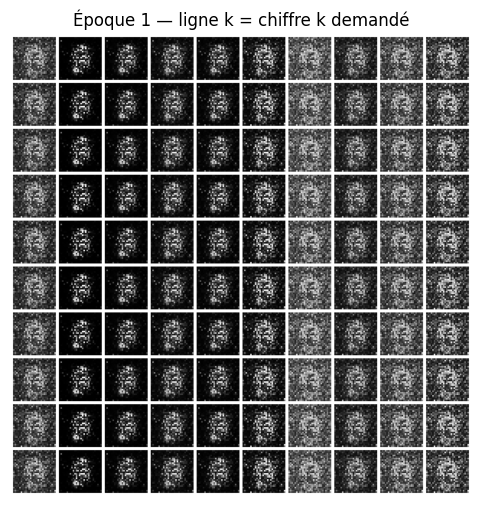

Époque  2/30 | loss_D = 0.771 | loss_G = 2.160
Époque  3/30 | loss_D = 0.781 | loss_G = 2.225
Époque  4/30 | loss_D = 0.676 | loss_G = 2.600
Époque  5/30 | loss_D = 0.646 | loss_G = 2.543


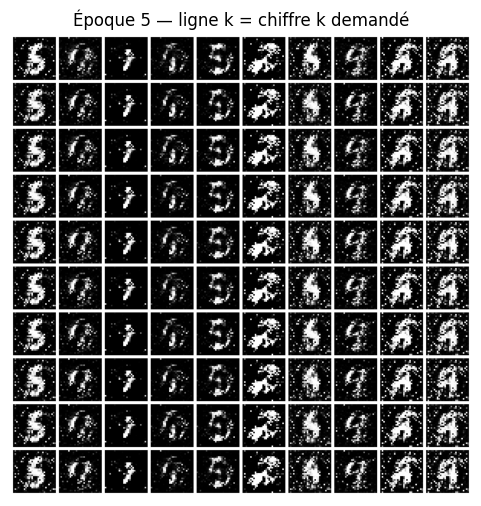

Époque  6/30 | loss_D = 0.706 | loss_G = 2.378
Époque  7/30 | loss_D = 0.774 | loss_G = 2.085
Époque  8/30 | loss_D = 0.873 | loss_G = 1.795
Époque  9/30 | loss_D = 0.927 | loss_G = 1.579
Époque 10/30 | loss_D = 0.954 | loss_G = 1.510
Époque 11/30 | loss_D = 1.013 | loss_G = 1.394
Époque 12/30 | loss_D = 1.090 | loss_G = 1.229
Époque 13/30 | loss_D = 1.125 | loss_G = 1.149
Époque 14/30 | loss_D = 1.154 | loss_G = 1.111
Époque 15/30 | loss_D = 1.170 | loss_G = 1.074
Époque 16/30 | loss_D = 1.195 | loss_G = 1.036
Époque 17/30 | loss_D = 1.214 | loss_G = 1.005
Époque 18/30 | loss_D = 1.231 | loss_G = 0.978
Époque 19/30 | loss_D = 1.234 | loss_G = 0.973
Époque 20/30 | loss_D = 1.253 | loss_G = 0.944
Époque 21/30 | loss_D = 1.251 | loss_G = 0.949
Époque 22/30 | loss_D = 1.269 | loss_G = 0.925
Époque 23/30 | loss_D = 1.272 | loss_G = 0.916
Époque 24/30 | loss_D = 1.280 | loss_G = 0.912
Époque 25/30 | loss_D = 1.287 | loss_G = 0.895
Époque 26/30 | loss_D = 1.292 | loss_G = 0.888
Époque 27/30 

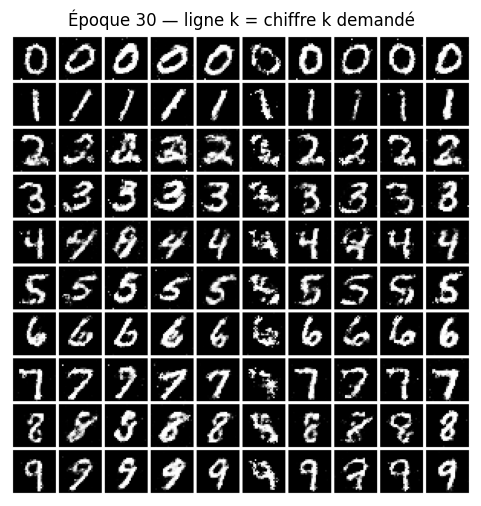

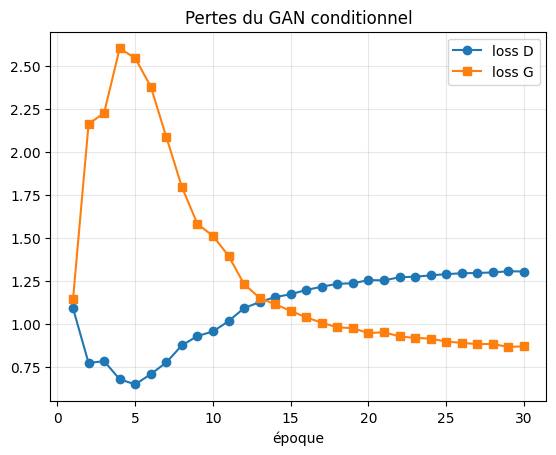

In [2]:
# =====================================================
# Question 7 — GAN conditionnel sur MNIST (y = classe en one-hot)
# =====================================================
# ---- Imports (nécessaires après un redémarrage de Colab) ----
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

# ---- Données MNIST, pixels entre -1 et 1 ----
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
loader = DataLoader(mnist, batch_size=128, shuffle=True, num_workers=0, drop_last=True)
image_dim, nb_classes, latent_dim = 28 * 28, 10, 100

# ---- Générateur conditionnel G(z, y) ----
class GenerateurConditionnel(nn.Module):
    def __init__(self):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Linear(latent_dim + nb_classes, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, image_dim), nn.Tanh())             # pixels entre -1 et 1
    def forward(self, z, y_oh):
        return self.reseau(torch.cat([z, y_oh], dim=1))        # concaténation [z, y]

# ---- Discriminateur conditionnel D(x, y) ----
class DiscriminateurConditionnel(nn.Module):
    def __init__(self):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Linear(image_dim + nb_classes, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(256, 1), nn.Sigmoid())
    def forward(self, x, y_oh):
        return self.reseau(torch.cat([x.view(x.size(0), -1), y_oh], dim=1))   # concaténation [x, y]

torch.manual_seed(0)
G = GenerateurConditionnel().to(device)
D = DiscriminateurConditionnel().to(device)
opt_G = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
critere = nn.BCELoss()

# ---- Codes fixes pour la grille : ligne = classe, colonne = même z ----
z_fixe = torch.randn(10, latent_dim, device=device).repeat(10, 1)
y_fixe_oh = F.one_hot(torch.arange(10, device=device).repeat_interleave(10), nb_classes).float()

def afficher_grille(Gmodele, titre):
    Gmodele.eval()
    with torch.no_grad():
        imgs = Gmodele(z_fixe, y_fixe_oh).view(-1, 1, 28, 28).cpu()
    Gmodele.train()
    g = torchvision.utils.make_grid(imgs, nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(6, 6)); plt.imshow(g.permute(1, 2, 0)); plt.axis("off"); plt.title(titre); plt.show()

# ---- Entraînement : 30 époques sur GPU, 15 sur CPU ----
nb_epoques = 30 if device.type == "cuda" else 15
hist_D, hist_G = [], []
for epoque in range(1, nb_epoques + 1):
    sD = sG = 0.0
    for x_reel, y in loader:
        b = x_reel.size(0)
        x_reel = x_reel.to(device)
        y_oh = F.one_hot(y, nb_classes).float().to(device)
        uns, zeros = torch.ones(b, 1, device=device), torch.zeros(b, 1, device=device)
        x_faux = G(torch.randn(b, latent_dim, device=device), y_oh)
        # pas de D : -[log D(x, y) + log(1 - D(G(z, y), y))], avec detach() pour ne pas toucher G
        loss_D = critere(D(x_reel, y_oh), uns) + critere(D(x_faux.detach(), y_oh), zeros)
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()
        # pas de G : perte non saturante -log D(G(z, y), y), plus stable que log(1 - D(G(z, y), y))
        loss_G = critere(D(x_faux, y_oh), uns)
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()
        sD += loss_D.item(); sG += loss_G.item()
    hist_D.append(sD / len(loader)); hist_G.append(sG / len(loader))
    print(f"Époque {epoque:2d}/{nb_epoques} | loss_D = {hist_D[-1]:.3f} | loss_G = {hist_G[-1]:.3f}")
    if epoque in [1, 5, nb_epoques]:
        afficher_grille(G, f"Époque {epoque} — ligne k = chiffre k demandé")

# ---- Courbes de perte ----
plt.plot(range(1, nb_epoques + 1), hist_D, "o-", label="loss D")
plt.plot(range(1, nb_epoques + 1), hist_G, "s-", label="loss G")
plt.xlabel("époque"); plt.title("Pertes du GAN conditionnel"); plt.legend(); plt.grid(alpha=0.3); plt.show()

In [3]:
# =====================================================
# Question 7 — Commentaire
# =====================================================
# La classe du chiffre (one-hot) est concaténée au bruit z en entrée de G, et à l'image en entrée de D.
# Pour G, on utilise la perte non saturante -log D(G(z, y), y) au lieu de log(1 - D(G(z, y), y)) :
# au début, D rejette facilement les fausses images et la seconde forme a un gradient presque nul.
# Les pertes montrent trois phases : D domine (époques 1-5 : loss_D descend à 0,65, loss_G monte à 2,60),
# puis G rattrape D (époques 5-20), enfin les pertes se stabilisent (loss_D = 1,30, loss_G = 0,87),
# près des valeurs d'équilibre théoriques 2 log 2 ≈ 1,39 et log 2 ≈ 0,69.
# Sur la grille, chaque ligne contient le chiffre demandé : le conditionnement est respecté. Chaque
# colonne utilise le même z et garde le même style (inclinaison, épaisseur) : y contrôle le chiffre,
# z contrôle le style. Les chiffres présentent un léger bruit granuleux, typique d'un générateur
# entièrement connecté qui ne tient pas compte de la structure spatiale de l'image.
# La question 8 (modèles convolutifs) est optionnelle et n'est pas traitée ici.
print("TP 3 terminé (questions 1 à 7).")

TP 3 terminé (questions 1 à 7).


[DCGAN] Époque  1/10 | loss_D = 0.646 | loss_G = 1.138
[DCGAN] Époque  2/10 | loss_D = 0.716 | loss_G = 0.835
[DCGAN] Époque  3/10 | loss_D = 0.521 | loss_G = 1.544
[DCGAN] Époque  4/10 | loss_D = 0.593 | loss_G = 0.966
[DCGAN] Époque  5/10 | loss_D = 0.753 | loss_G = 3.074
[DCGAN] Époque  6/10 | loss_D = 0.626 | loss_G = 1.169
[DCGAN] Époque  7/10 | loss_D = 0.595 | loss_G = 1.006
[DCGAN] Époque  8/10 | loss_D = 0.655 | loss_G = 2.729
[DCGAN] Époque  9/10 | loss_D = 0.832 | loss_G = 0.982
[DCGAN] Époque 10/10 | loss_D = 0.557 | loss_G = 1.501
Précision de LeNet5 sur le test MNIST : 98.54 %
Forme renvoyée par code2image : torch.Size([16, 28, 28])


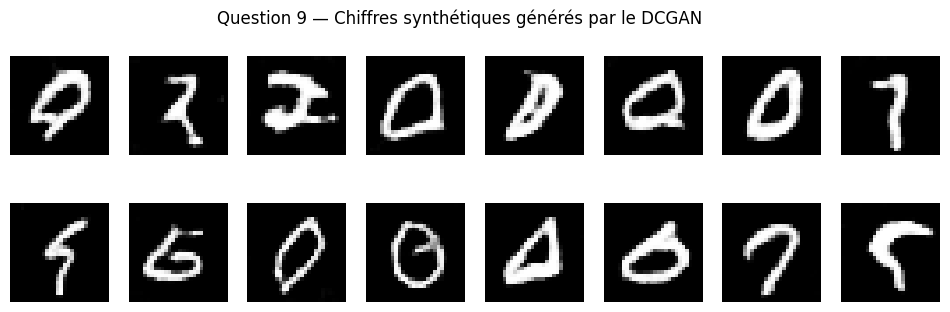

In [4]:
# =====================================================
# TP 2 — Espace latent des GAN
# 2.1 Préparation : DCGAN (espace latent de dimension 100) et classifieur LeNet5
# Les modèles préentraînés n'étant pas fournis, nous les entraînons nous-mêmes sur MNIST.
# =====================================================
nz = 100                                         # dimension de l'espace latent

G_dc = nn.Sequential(                            # générateur DCGAN : z (100x1x1) -> image 1x28x28
    nn.ConvTranspose2d(nz, 128, 7, 1, 0, bias=False), nn.BatchNorm2d(128), nn.ReLU(),   # -> 128x7x7
    nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),    # -> 64x14x14
    nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh()).to(device)                          # -> 1x28x28
D_dc = nn.Sequential(                            # discriminateur DCGAN : image -> probabilité
    nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),                                       # -> 64x14x14
    nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),    # -> 128x7x7
    nn.Conv2d(128, 1, 7, 1, 0), nn.Flatten(), nn.Sigmoid()).to(device)                  # -> 1

torch.manual_seed(0)
optG = optim.Adam(G_dc.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = optim.Adam(D_dc.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCELoss()
for epoque in range(1, 11):                      # 10 époques
    for x, _ in loader:                          # loader MNIST de la question 7 (pixels entre -1 et 1)
        x = x.to(device); b = x.size(0)
        uns, zeros = torch.ones(b, 1, device=device), torch.zeros(b, 1, device=device)
        faux = G_dc(torch.randn(b, nz, 1, 1, device=device))     # z ~ N(0, I)
        lD = bce(D_dc(x), uns) + bce(D_dc(faux.detach()), zeros)
        optD.zero_grad(); lD.backward(); optD.step()
        lG = bce(D_dc(faux), uns)
        optG.zero_grad(); lG.backward(); optG.step()
    print(f"[DCGAN] Époque {epoque:2d}/10 | loss_D = {lD.item():.3f} | loss_G = {lG.item():.3f}")
G_dc.eval()

# ---- LeNet5 (classifieur de chiffres), entraîné sur les mêmes images (pixels entre -1 et 1) ----
lenet = nn.Sequential(
    nn.Conv2d(1, 6, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),    # -> 6x14x14
    nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),               # -> 16x5x5
    nn.Flatten(), nn.Linear(16 * 5 * 5, 120), nn.ReLU(),
    nn.Linear(120, 84), nn.ReLU(), nn.Linear(84, 10)).to(device)
mnist_test = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)
test_loader_m = DataLoader(mnist_test, batch_size=256, shuffle=False, num_workers=0)
opt_l = optim.Adam(lenet.parameters(), lr=1e-3)
for epoque in range(3):
    for x, y in loader:
        perte = F.cross_entropy(lenet(x.to(device)), y.to(device))
        opt_l.zero_grad(); perte.backward(); opt_l.step()
lenet.eval(); bonnes = 0
with torch.no_grad():
    for x, y in test_loader_m:
        bonnes += (lenet(x.to(device)).argmax(1).cpu() == y).sum().item()
print(f"Précision de LeNet5 sur le test MNIST : {100 * bonnes / len(mnist_test):.2f} %")

# =====================================================
# Question 9 — Fonction code2image : codes z (n, 100) ou (n, 100, 1, 1) -> images (n, h, w)
# =====================================================
def code2image(z):
    z = z.view(-1, nz, 1, 1).to(device)          # accepte (n, 100) ou (n, 100, 1, 1)
    with torch.no_grad():
        return G_dc(z).squeeze(1).cpu()          # (n, 28, 28), pixels entre -1 et 1

torch.manual_seed(0)
imgs = code2image(torch.randn(16, nz))
print("Forme renvoyée par code2image :", imgs.shape)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img in zip(axes.flat, imgs):
    ax.imshow(img, cmap="gray"); ax.axis("off")
plt.suptitle("Question 9 — Chiffres synthétiques générés par le DCGAN"); plt.show()

Occurrences par classe (synthétiques) : [135  56  60 128  43 133  95 126  56 168]
Proportions attendues d'après MNIST (pour 1000 images) : [ 99 112  99 102  97  90  99 104  98  99]


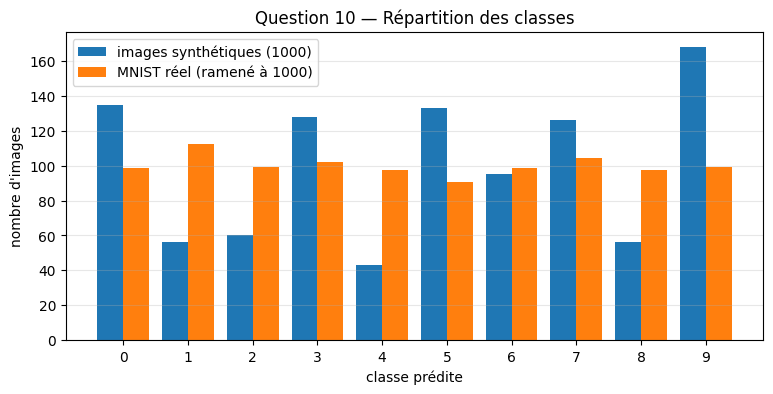

SVM entraînée sur le réel       -> test réel        : 90.4 %
SVM entraînée sur le réel       -> test synthétique : 63.2 %
SVM entraînée sur le synthétique -> test réel        : 70.7 %


In [5]:
# =====================================================
# Question 10 — Distribution des classes synthétiques
# =====================================================
torch.manual_seed(0)
Z = torch.randn(1000, nz)                                  # 1000 codes dans l'espace latent
imgs_syn = code2image(Z)                                   # 1000 images synthétiques (1000, 28, 28)
with torch.no_grad():
    labels_syn = lenet(imgs_syn.unsqueeze(1).to(device)).argmax(1).cpu().numpy()   # classe prédite par LeNet5

comptes_syn = np.bincount(labels_syn, minlength=10)
comptes_reels = np.bincount(mnist.targets.numpy(), minlength=10)
prop_reelles = comptes_reels / comptes_reels.sum()
print("Occurrences par classe (synthétiques) :", comptes_syn)
print("Proportions attendues d'après MNIST (pour 1000 images) :", (1000 * prop_reelles).round().astype(int))

largeur = 0.4
plt.figure(figsize=(9, 4))
plt.bar(np.arange(10) - largeur / 2, comptes_syn, largeur, label="images synthétiques (1000)")
plt.bar(np.arange(10) + largeur / 2, 1000 * prop_reelles, largeur, label="MNIST réel (ramené à 1000)")
plt.xticks(range(10)); plt.xlabel("classe prédite"); plt.ylabel("nombre d'images")
plt.title("Question 10 — Répartition des classes"); plt.legend(); plt.grid(axis="y", alpha=0.3); plt.show()

# =====================================================
# Question 11 — Séparabilité des classes avec une SVM linéaire
# =====================================================
from sklearn.svm import LinearSVC

def vers_vecteurs(images):                                 # images entre -1 et 1 -> vecteurs de 784 valeurs entre 0 et 1
    return ((images.reshape(len(images), -1) + 1) / 2).numpy()

n_train = 10000                                            # sous-ensemble pour un entraînement rapide
X_reel_train = vers_vecteurs(mnist.data[:n_train].float() / 127.5 - 1)
y_reel_train = mnist.targets[:n_train].numpy()
X_reel_test = vers_vecteurs(mnist_test.data.float() / 127.5 - 1)
y_reel_test = mnist_test.targets.numpy()
X_syn = vers_vecteurs(imgs_syn)                            # 1. images synthétiques étiquetées par LeNet5

svm_reel = LinearSVC(dual=False, C=0.1, max_iter=2000).fit(X_reel_train, y_reel_train)   # 2. SVM apprise sur le réel
score_reel_reel = svm_reel.score(X_reel_test, y_reel_test)                               # 3. évaluée sur le test réel
score_reel_syn = svm_reel.score(X_syn, labels_syn)                                       # 4. évaluée sur le synthétique
svm_syn = LinearSVC(dual=False, C=0.1, max_iter=2000).fit(X_syn, labels_syn)             # 5. SVM apprise sur le synthétique
score_syn_reel = svm_syn.score(X_reel_test, y_reel_test)                                 #    évaluée sur le test réel

print(f"SVM entraînée sur le réel       -> test réel        : {100 * score_reel_reel:.1f} %")
print(f"SVM entraînée sur le réel       -> test synthétique : {100 * score_reel_syn:.1f} %")
print(f"SVM entraînée sur le synthétique -> test réel        : {100 * score_syn_reel:.1f} %")

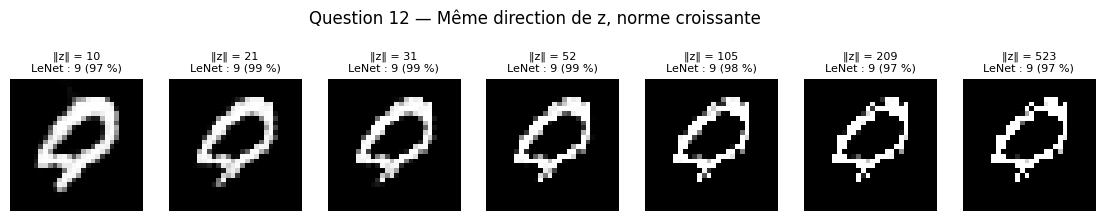

Norme typique d'un z ~ N(0, I_100) : environ √100 = 10 (ici ‖z0‖ = 10.5)


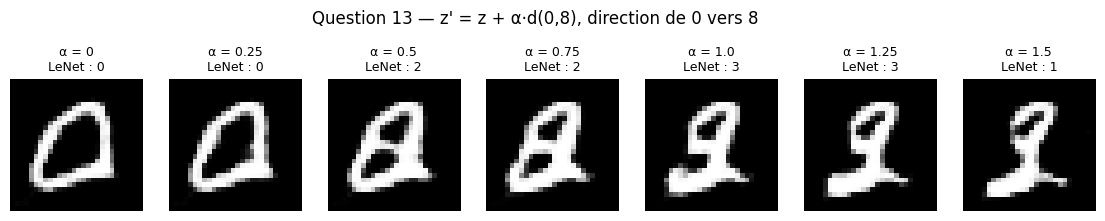

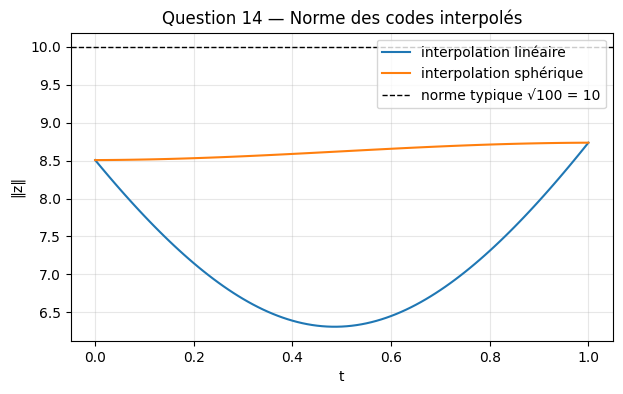

Norme minimale : linéaire = 6.31 | sphérique = 8.51


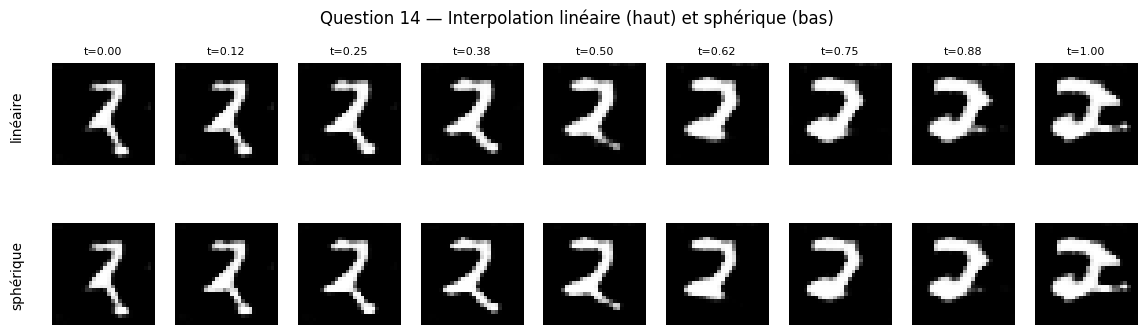

TP 3 complet : questions 1 à 7 et 9 à 14 (la question 8 est optionnelle).


In [6]:
# =====================================================
# Question 10 — Commentaire
# =====================================================
# Dans MNIST, chaque chiffre représente environ 10 % des images. Les 1000 images synthétiques ne sont pas
# équilibrées : certains chiffres sont sur-représentés (9 : 168, 0 : 135, 5 : 133, 3 : 128, 7 : 126) et
# d'autres sous-représentés (4 : 43, 1 : 56, 8 : 56, 2 : 60). Le GAN ne couvre donc pas uniformément la
# distribution réelle : c'est un effondrement de modes partiel (mode collapse), qui s'ajoute aux erreurs
# possibles de LeNet5 sur des images ambiguës.
#
# =====================================================
# Question 11 — Commentaire
# =====================================================
# La SVM linéaire apprise sur le réel obtient 90,4 % sur le test réel, mais seulement 63,2 % sur les images
# synthétiques : celles-ci sont moins bien séparables linéairement (formes ambiguës, artefacts, styles
# différents des vrais chiffres). Une SVM apprise sur les images synthétiques obtient 70,7 % sur le test
# réel : les données générées contiennent une information utile sur les classes, mais elles ne couvrent pas
# toute la diversité des vraies données (mode collapse, classes déséquilibrées). La distribution apprise
# par le GAN reste donc différente de la distribution réelle.

# =====================================================
# Question 12 — Effet de la norme de z
# =====================================================
facteurs = [1, 2, 3, 5, 10, 20, 50]
z0 = Z[0:1]                                                # un code de départ
imgs_norme = code2image(torch.cat([f * z0 for f in facteurs]))
with torch.no_grad():
    conf = F.softmax(lenet(imgs_norme.unsqueeze(1).to(device)), 1).max(1)
fig, axes = plt.subplots(1, len(facteurs), figsize=(14, 2.8))
for ax, img, f, c, p in zip(axes, imgs_norme, facteurs, conf.values.cpu(), conf.indices.cpu()):
    ax.imshow(img, cmap="gray"); ax.axis("off")
    ax.set_title(f"‖z‖ = {f * z0.norm().item():.0f}\nLeNet : {p.item()} ({100 * c.item():.0f} %)", fontsize=8)
plt.suptitle("Question 12 — Même direction de z, norme croissante"); plt.show()
print(f"Norme typique d'un z ~ N(0, I_100) : environ √100 = 10 (ici ‖z0‖ = {z0.norm().item():.1f})")
# Commentaire : les codes vus pendant l'apprentissage ont une norme proche de 10 (pour z ~ N(0, I_100),
# ‖z‖ ≈ √100). Quand la norme devient très grande, z sort de la région apprise : les activations saturent,
# l'image devient très contrastée, déformée, puis ne ressemble plus à un chiffre (taches, traits épais).

# =====================================================
# Question 13 — Directions sémantiques entre classes
# =====================================================
barycentres = torch.stack([Z[torch.tensor(labels_syn) == i].mean(0) for i in range(10)])   # m_i
i, j = 0, 8
d_ij = barycentres[j] - barycentres[i]                     # direction d_{0,8} = m_8 - m_0
indices_0 = np.where(labels_syn == i)[0]
z_depart = Z[indices_0[0]]                                 # un code qui donne un 0
alphas = [0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]
imgs_dir = code2image(torch.stack([z_depart + a * d_ij for a in alphas]))
with torch.no_grad():
    pred_dir = lenet(imgs_dir.unsqueeze(1).to(device)).argmax(1).cpu()
fig, axes = plt.subplots(1, len(alphas), figsize=(14, 2.8))
for ax, img, a, p in zip(axes, imgs_dir, alphas, pred_dir):
    ax.imshow(img, cmap="gray"); ax.axis("off"); ax.set_title(f"α = {a}\nLeNet : {p.item()}", fontsize=9)
plt.suptitle(f"Question 13 — z' = z + α·d({i},{j}), direction de {i} vers {j}"); plt.show()
# Commentaire : en suivant la direction m_8 - m_0, l'image part d'un 0 et se transforme progressivement :
# la boucle se resserre au milieu, ce qui fait apparaître la forme d'un 8 ; LeNet5 change de classe pour
# α assez grand. Les barycentres des classes définissent donc des directions sémantiques dans l'espace
# latent. Pour α trop grand, on s'éloigne de la région apprise et l'image se dégrade.

# =====================================================
# Question 14 — Interpolation sphérique (slerp) vs linéaire (lerp)
# =====================================================
def slerp(z1, z2, t):
    omega = torch.acos(torch.clamp((z1 / z1.norm()) @ (z2 / z2.norm()), -1, 1))   # angle entre z1 et z2
    return (torch.sin((1 - t) * omega) * z1 + torch.sin(t * omega) * z2) / torch.sin(omega)

z1, z2 = Z[1], Z[2]
ts = torch.linspace(0, 1, 9)
lerp_codes = torch.stack([(1 - t) * z1 + t * z2 for t in ts])
slerp_codes = torch.stack([slerp(z1, z2, t) for t in ts])
t_fin = torch.linspace(0, 1, 101)
plt.figure(figsize=(7, 4))
plt.plot(t_fin, [((1 - t) * z1 + t * z2).norm() for t in t_fin], label="interpolation linéaire")
plt.plot(t_fin, [slerp(z1, z2, t).norm() for t in t_fin], label="interpolation sphérique")
plt.axhline(10, color="k", ls="--", lw=1, label="norme typique √100 = 10")
plt.xlabel("t"); plt.ylabel("‖z‖"); plt.title("Question 14 — Norme des codes interpolés"); plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Norme minimale : linéaire = {min(c.norm() for c in lerp_codes):.2f} | sphérique = {min(c.norm() for c in slerp_codes):.2f}")

imgs_l, imgs_s = code2image(lerp_codes), code2image(slerp_codes)
fig, axes = plt.subplots(2, len(ts), figsize=(14, 3.8))
for k in range(len(ts)):
    axes[0, k].imshow(imgs_l[k], cmap="gray"); axes[0, k].axis("off"); axes[0, k].set_title(f"t={ts[k]:.2f}", fontsize=8)
    axes[1, k].imshow(imgs_s[k], cmap="gray"); axes[1, k].axis("off")
axes[0, 0].text(-12, 14, "linéaire", rotation=90, va="center"); axes[1, 0].text(-12, 14, "sphérique", rotation=90, va="center")
plt.suptitle("Question 14 — Interpolation linéaire (haut) et sphérique (bas)"); plt.show()
# Commentaire : pour z ~ N(0, I_100), presque toute la masse de probabilité est concentrée près de la sphère
# de rayon √100 = 10. L'interpolation linéaire coupe à travers la boule : au milieu, la norme chute (environ
# 10/√2 ≈ 7 pour deux codes presque orthogonaux), dans une zone quasiment jamais vue pendant l'apprentissage,
# ce qui donne des images intermédiaires plus pâles ou moins nettes. L'interpolation sphérique garde une
# norme proche de 10 tout le long : les images intermédiaires restent dans la région typique et sont plus
# régulières et plus réalistes.
print("TP 3 complet : questions 1 à 7 et 9 à 14 (la question 8 est optionnelle).")

Paramètres G conv : 841025 | D conv : 149057
Paramètres G dense : 1488912 | D dense : 538625
[GAN conv] Époque  1/15 | loss_D = 0.557 | loss_G = 2.119
[GAN conv] Époque  2/15 | loss_D = 0.545 | loss_G = 1.872
[GAN conv] Époque  3/15 | loss_D = 0.390 | loss_G = 2.330
[GAN conv] Époque  4/15 | loss_D = 0.397 | loss_G = 2.454
[GAN conv] Époque  5/15 | loss_D = 0.462 | loss_G = 2.360
[GAN conv] Époque  6/15 | loss_D = 0.531 | loss_G = 2.186
[GAN conv] Époque  7/15 | loss_D = 0.581 | loss_G = 2.066
[GAN conv] Époque  8/15 | loss_D = 0.621 | loss_G = 2.003
[GAN conv] Époque  9/15 | loss_D = 0.665 | loss_G = 1.932
[GAN conv] Époque 10/15 | loss_D = 0.645 | loss_G = 1.936
[GAN conv] Époque 11/15 | loss_D = 0.673 | loss_G = 1.913
[GAN conv] Époque 12/15 | loss_D = 0.678 | loss_G = 1.903
[GAN conv] Époque 13/15 | loss_D = 0.684 | loss_G = 1.906
[GAN conv] Époque 14/15 | loss_D = 0.684 | loss_G = 1.905
[GAN conv] Époque 15/15 | loss_D = 0.719 | loss_G = 1.890
Fidélité au chiffre demandé (LeNet5) 

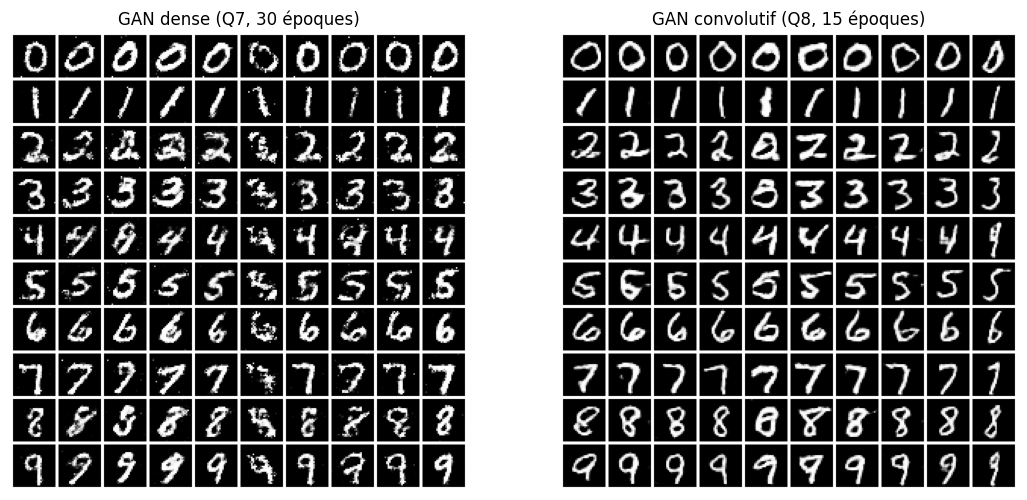

Question 8 terminée : toutes les questions du TP 3 sont faites.


In [7]:
# =====================================================
# Question 8 (optionnelle) — GAN conditionnel convolutif
# G : linéaire puis ConvTranspose2d (7 -> 14 -> 28) ; D : Conv2d de stride 2 (28 -> 14 -> 7)
# =====================================================
class GenerateurConvCond(nn.Module):             # G(z, y) convolutionnel
    def __init__(self):
        super().__init__()
        self.lineaire = nn.Sequential(
            nn.Linear(latent_dim + nb_classes, 128 * 7 * 7), nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),   # 7x7 -> 14x14
            nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1), nn.Tanh())                        # 14x14 -> 28x28
    def forward(self, z, y_oh):
        h = self.lineaire(torch.cat([z, y_oh], dim=1)).view(-1, 128, 7, 7)   # [z, y] -> bloc 128x7x7
        return self.deconv(h)

class DiscriminateurConvCond(nn.Module):         # D(x, y) convolutionnel
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1 + nb_classes, 64, 4, stride=2, padding=1), nn.LeakyReLU(0.2),            # 11x28x28 -> 64x14x14
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),  # -> 128x7x7
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1), nn.Sigmoid())
    def forward(self, x, y_oh):
        cartes_y = y_oh[:, :, None, None].expand(-1, -1, 28, 28)       # classe -> 10 cartes 28x28 constantes
        return self.conv(torch.cat([x.view(-1, 1, 28, 28), cartes_y], dim=1))

torch.manual_seed(0)
G_conv = GenerateurConvCond().to(device); D_conv = DiscriminateurConvCond().to(device)
print("Paramètres G conv :", sum(p.numel() for p in G_conv.parameters()), "| D conv :", sum(p.numel() for p in D_conv.parameters()))
print("Paramètres G dense :", sum(p.numel() for p in G.parameters()), "| D dense :", sum(p.numel() for p in D.parameters()))
opt_Gc = optim.Adam(G_conv.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_Dc = optim.Adam(D_conv.parameters(), lr=2e-4, betas=(0.5, 0.999))

nb_epoques_conv = 15
for epoque in range(1, nb_epoques_conv + 1):
    sD = sG = 0.0
    for x_reel, y in loader:
        b = x_reel.size(0)
        x_reel = x_reel.to(device); y_oh = F.one_hot(y, nb_classes).float().to(device)
        uns, zeros = torch.ones(b, 1, device=device), torch.zeros(b, 1, device=device)
        x_faux = G_conv(torch.randn(b, latent_dim, device=device), y_oh)
        loss_D = critere(D_conv(x_reel, y_oh), uns) + critere(D_conv(x_faux.detach(), y_oh), zeros)
        opt_Dc.zero_grad(); loss_D.backward(); opt_Dc.step()
        loss_G = critere(D_conv(x_faux, y_oh), uns)
        opt_Gc.zero_grad(); loss_G.backward(); opt_Gc.step()
        sD += loss_D.item(); sG += loss_G.item()
    print(f"[GAN conv] Époque {epoque:2d}/{nb_epoques_conv} | loss_D = {sD/len(loader):.3f} | loss_G = {sG/len(loader):.3f}")

# ---- Comparaison : GAN dense (Q7) vs GAN convolutif (Q8), mêmes z et mêmes classes ----
G.eval(); G_conv.eval()
with torch.no_grad():
    img_dense = G(z_fixe, y_fixe_oh).view(-1, 1, 28, 28).cpu()
    img_conv = G_conv(z_fixe, y_fixe_oh).cpu()
    # fidélité au conditionnement mesurée par LeNet5 (même classifieur qu'aux questions 10 et 11)
    zt = torch.randn(1000, latent_dim, device=device)
    yt = torch.arange(10, device=device).repeat(100)
    yt_oh = F.one_hot(yt, nb_classes).float()
    fid_dense = (lenet(G(zt, yt_oh).view(-1, 1, 28, 28)).argmax(1) == yt).float().mean().item()
    fid_conv = (lenet(G_conv(zt, yt_oh)).argmax(1) == yt).float().mean().item()
print(f"Fidélité au chiffre demandé (LeNet5) — GAN dense : {100 * fid_dense:.1f} % | GAN conv : {100 * fid_conv:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, imgs, titre in zip(axes, [img_dense, img_conv], ["GAN dense (Q7, 30 époques)", f"GAN convolutif (Q8, {nb_epoques_conv} époques)"]):
    g = torchvision.utils.make_grid(imgs, nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
    ax.imshow(g.permute(1, 2, 0)); ax.set_title(titre); ax.axis("off")
plt.show()
print("Question 8 terminée : toutes les questions du TP 3 sont faites.")

In [8]:
# =====================================================
# Question 8 — Commentaire
# =====================================================
# Le GAN conditionnel convolutif utilise une couche linéaire puis deux ConvTranspose2d dans le générateur
# (7x7 -> 14x14 -> 28x28), et deux Conv2d de stride 2 dans le discriminateur, la classe y étant injectée
# sous forme de 10 cartes constantes concaténées à l'image. Il compte deux fois moins de paramètres que
# le GAN dense (990 082 contre 2 027 537 pour G + D).
# Ses pertes se stabilisent loin de l'équilibre (loss_D ≈ 0,72, loss_G ≈ 1,89) : le discriminateur
# convolutif détecte efficacement les défauts locaux des images. Ces pertes ne mesurent pas la qualité :
# avec seulement 15 époques (contre 30), le GAN convolutif produit des chiffres reconnus comme la bonne
# classe par LeNet5 dans 98,5 % des cas, contre 95,0 % pour le GAN dense. Les convolutions transposées
# génèrent chaque pixel à partir de ses voisins (traits plus continus), et le partage des poids rend le
# modèle plus efficace avec moins de paramètres.
print("TP 3 complet : toutes les questions (1 à 14) sont faites.")

TP 3 complet : toutes les questions (1 à 14) sont faites.
